In [189]:
import numpy as np
import matplotlib.pyplot as plt
import sympy

In [190]:
#Commenting out old "idea code"
"""
numberList = np.arange(0, 100, 1)
print("3:")
for i in numberList:
    if i%3==0:
        print(i)
print("5:")
talliste2 = np.arange(0, 101, 1)
for i in talliste2:
    if i%5==0:
        print(i)
print("primes")

"""


numberList = np.arange(2, 101, 1)

#print(numberList)
# for my implementation I have to start with a first prime
primes = np.array([2])
for i in numberList:
#start testing a new number
    divisor = 0
    #Check if it has any clean divisors, in a fairly (if I say so myself) elegant way
    remainder = (i%primes).min()
    if remainder != 0: # i.e it has no divisors
        
        #add any found primes to the prime set
        array = np.array([i])
        primes = np.append(primes,array)
        print(i, "is prime")
    else:
        print(i, "is not prime")
print(primes)

2 is not prime
3 is prime
4 is not prime
5 is prime
6 is not prime
7 is prime
8 is not prime
9 is not prime
10 is not prime
11 is prime
12 is not prime
13 is prime
14 is not prime
15 is not prime
16 is not prime
17 is prime
18 is not prime
19 is prime
20 is not prime
21 is not prime
22 is not prime
23 is prime
24 is not prime
25 is not prime
26 is not prime
27 is not prime
28 is not prime
29 is prime
30 is not prime
31 is prime
32 is not prime
33 is not prime
34 is not prime
35 is not prime
36 is not prime
37 is prime
38 is not prime
39 is not prime
40 is not prime
41 is prime
42 is not prime
43 is prime
44 is not prime
45 is not prime
46 is not prime
47 is prime
48 is not prime
49 is not prime
50 is not prime
51 is not prime
52 is not prime
53 is prime
54 is not prime
55 is not prime
56 is not prime
57 is not prime
58 is not prime
59 is prime
60 is not prime
61 is prime
62 is not prime
63 is not prime
64 is not prime
65 is not prime
66 is not prime
67 is prime
68 is not prime
69 is no

In [191]:
# time to test it, sympy has a function to list primes

Answer = list(sympy.primerange(0, 100))
succes = 1
for i in range(len(primes)):
    if Answer[i] != primes[i]: 
        succes = 0
        print("failure")
if succes == 1:
    print("succes")

succes


2.4 simulation

In [192]:
a = np.arange(0,3)
print(a)

[0 1 2]


In [193]:
# I will be working with a 10x10 grid
# true = alive
#class Tile:
 #   def __init__(self, isLive):
     #   status = isLive
    #def update()

#https://www.geeksforgeeks.org/python/slice-a-2d-array-in-python/
def checkneighbours(state,x,y):
    x1 = 0
    x2 = 0
    if x == 0:
        x1 = 0
    else:
        x1 = x-1
    if x == sizeX-1:
        x2 = sizeX
    else:
        x2 =x+2

    
    y1 = 0
    y2 = 0
    ##ADding comments
    if y == 0:
            y1 = 0
    else:
         y1 = y-1
    if y == sizeY-1:
        y2 = sizeY
    else:
        y2 =y+2
    #y_range = [np.max(y-1,0), np.min(sizeY-1, y+1)]
    #print(x1,x2, y1,y2)
    returnVal = 0
    itt = 0
    for i in np.arange(x1,x2):
         for j in np.arange(y1,y2):
              returnVal += state[i,j]
              itt += 1
    #print(returnVal)
    #print("itt", itt)
    return returnVal

    #initialise as long strong of each line
def loadData(file_name):
    lines = np.genfromtxt(file_name, dtype = str, comments = None)
    #convert to a 2d array with numerical values

    grid = np.array([[1 if c =='#' else 0 for c in row] for row in lines])
    #This works by itterating through each string and converting those into a value map, where # = 1 and 0 = . 
    #print(grid.shape)
    sizeX = grid.shape[0]
    sizeY = grid.shape[1]
    #print(sizeX)
    return grid, sizeX, sizeY


In [204]:
def simulate_life(grid,sizeX,sizeY, itt):
    #print(data)


    life = []
    life.append(grid)
    #print(life[0,:,:])
    cycles = itt
    lives_hist = []
    for k in range(cycles):
        next_life = np.zeros(shape=(sizeX,sizeY))
        lives = 0
        for i, row in enumerate(life[k]):
            for j, cell in enumerate(row):
                #print("row", i, "col", j, "value", cell)
                neighbours = checkneighbours(life[k],i,j)-cell
                #print(cell,neighbours)
                
                if cell ==1 and (neighbours==3 or neighbours == 2):
                    next_life[i,j] = 1 
                    #print(f'{i},{j} survived')
                elif cell == 0 and neighbours == 3:
                    next_life[i,j] = 1
                    #print(f'{i},{j} spawned')
                else:
                    next_life[i,j] = 0
        life.append(next_life)
        lives_hist.append(np.sum(next_life))
        #print(f'{k}th cycle complted')
    print(lives_hist)
    return life, lives_hist

In [205]:
def display_life(life, lives_hist, lifeCount = False, Show = True):
    prints = []
    #go through all life cycles and make a array with "#" instead of 1 and "." instead of 0
    for i in (life):
        slide =  np.zeros(shape = i.shape, dtype = str)
        for j in range(i.shape[0]):
            for k in range(i.shape[1]):
                if i[j,k] == 1:
                    slide[j,k] = "#"
                else:
                    slide[j,k] = "."
        prints.append(slide)
    #3
    if Show == True:
        for i in prints:
            print(" ")
            print(i)  
    elif(Show == isinstance(Show,list)):
        for i in Show: 
            print(" ")
            print(prints[i])
    else:
        print("incorrect file type for print try integer list or Bool (True)")
    #4.
    if lifeCount == True:
        plt.plot(range(len(lives_hist)), lives_hist, ".")
        plt.xlabel("Generation")
        plt.ylabel("lives")

In [206]:
def LetItLive(str, lifeCount = False,Show = True, itt = 10):
    a, b,c =loadData(str)
    d,e = simulate_life(a,b,c, itt) 
    display_life(d,e, lifeCount,Show)
    
LetItLive("blinker.txt")
    

[np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0), np.float64(3.0)]
 
[['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '#' '#' '#' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']]


[np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0)]
 
[['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '#' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '#' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '#' '#' '#' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']]


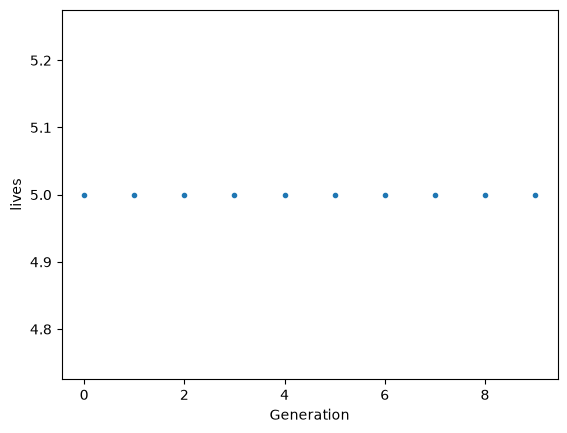

In [ ]:
LetItLive("glider.txt")

[np.float64(6.0), np.float64(7.0), np.float64(9.0), np.float64(8.0), np.float64(9.0), np.float64(12.0), np.float64(11.0), np.float64(18.0), np.float64(11.0), np.float64(11.0), np.float64(10.0), np.float64(13.0), np.float64(16.0), np.float64(19.0), np.float64(19.0), np.float64(22.0), np.float64(24.0), np.float64(30.0), np.float64(24.0), np.float64(35.0)]
 
[['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '#' '#' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '#' '#' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '#' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.']
 ['.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.' '.

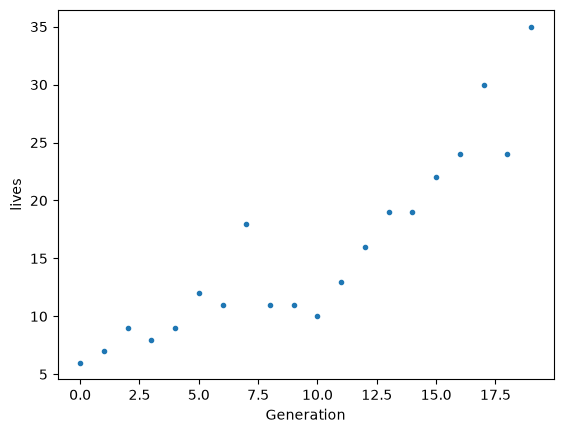

In [210]:
LetItLive("pentomino.txt", lifeCount=True, itt = 20)

Questions:
1: Do all config become stationary - no, blinker alternates between to states

2: Yes, the glider moves through the grid

3: No, pentoimino grows in number